In [1]:
#  Import Libraries for dataset analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
#  Load dataset
pathfile="Restaurant_revenue (1).csv"
if os.path.exists(pathfile):
    df=pd.read_csv(pathfile)
else:print("FileNotFoundError")

In [3]:
#  Shape of dataset
df.shape

(1000, 8)

In [4]:
#  dataset info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Number_of_Customers        1000 non-null   int64  
 1   Menu_Price                 1000 non-null   float64
 2   Marketing_Spend            1000 non-null   float64
 3   Cuisine_Type               1000 non-null   str    
 4   Average_Customer_Spending  1000 non-null   float64
 5   Promotions                 1000 non-null   int64  
 6   Reviews                    1000 non-null   int64  
 7   Monthly_Revenue            1000 non-null   float64
dtypes: float64(4), int64(3), str(1)
memory usage: 70.0 KB


In [5]:
# First five rows
df.head()

,Number_of_Customers,Menu_Price,Marketing_Spend,Cuisine_Type,Average_Customer_Spending,Promotions,Reviews,Monthly_Revenue
0,61,43.117635,12.663793,Japanese,36.236133,0,45,350.912040
1,24,40.020077,4.577892,Italian,17.952562,0,36,221.319091
2,81,41.981485,4.652911,Japanese,22.600420,1,91,326.529763
3,70,43.005307,4.416053,Italian,18.984098,1,59,348.190573
4,30,17.456199,3.475052,Italian,12.766143,1,30,185.009121


In [6]:
# Last five rows
df.tail()

,Number_of_Customers,Menu_Price,Marketing_Spend,Cuisine_Type,Average_Customer_Spending,Promotions,Reviews,Monthly_Revenue
995,73,41.307842,12.122931,Japanese,19.033585,1,40,249.312034
996,31,20.615496,5.822885,Mexican,17.040990,0,57,110.228767
997,69,17.110656,4.141898,Japanese,44.649315,0,55,312.212552
998,73,37.664722,3.046556,Japanese,27.767358,0,23,272.482204
999,81,34.722067,17.989104,Italian,15.482112,1,72,379.973072


In [7]:
#  Investigate duplicated values
df.duplicated().sum()

np.int64(0)

In [8]:
#  Investigate data inconsistence
for col in df.select_dtypes(include="str").columns:
    print(df[col].value_counts())
    print()

Cuisine_Type
Japanese    262
American    256
Mexican     250
Italian     232
Name: count, dtype: int64



In [9]:
# Investigate impossible values
impossible_value_columns=df.select_dtypes(include="number").columns
non_zero_columns=impossible_value_columns.drop(["Promotions","Marketing_Spend","Reviews"])
for col in non_zero_columns:
    print(col)
    a=df[col]<=0
    if a.count()>0:
        print(df[col][a])
    else:
        print("No Impossible values for ",col)
    print()

Number_of_Customers
Series([], Name: Number_of_Customers, dtype: int64)

Menu_Price
Series([], Name: Menu_Price, dtype: float64)

Average_Customer_Spending
Series([], Name: Average_Customer_Spending, dtype: float64)

Monthly_Revenue
54    -28.977809
104   -27.610276
110   -25.453430
605   -28.920890
735    -7.627382
Name: Monthly_Revenue, dtype: float64



In [10]:
non_negative_columns=df[["Marketing_Spend","Reviews"]]
for col in non_negative_columns:
    print(col)
    a=df[col]<0
    if a.sum()>0:
        print(df[col][a])
    else:
        print("No Impossible value for ",col)
    print()


Marketing_Spend
No Impossible value for  Marketing_Spend

Reviews
No Impossible value for  Reviews



In [11]:
# Investigate null values
df.isnull().sum()

Number_of_Customers          0
Menu_Price                   0
Marketing_Spend              0
Cuisine_Type                 0
Average_Customer_Spending    0
Promotions                   0
Reviews                      0
Monthly_Revenue              0
dtype: int64

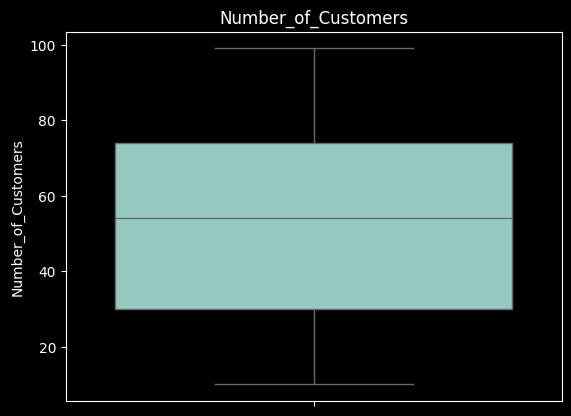

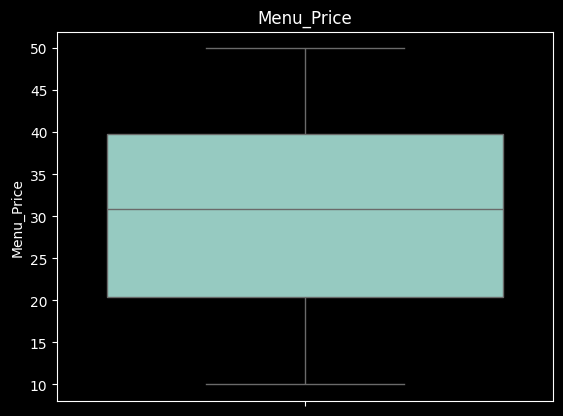

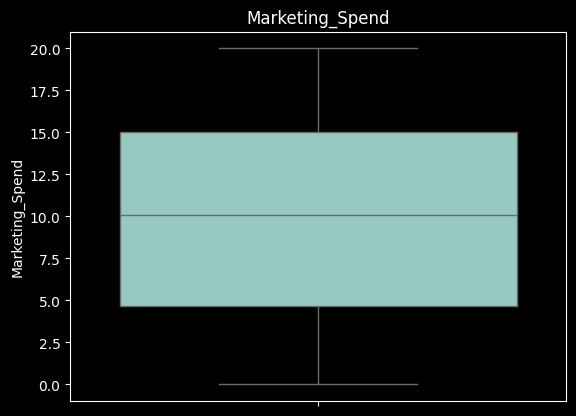

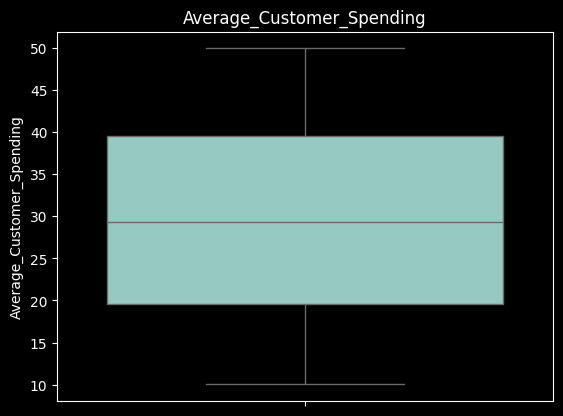

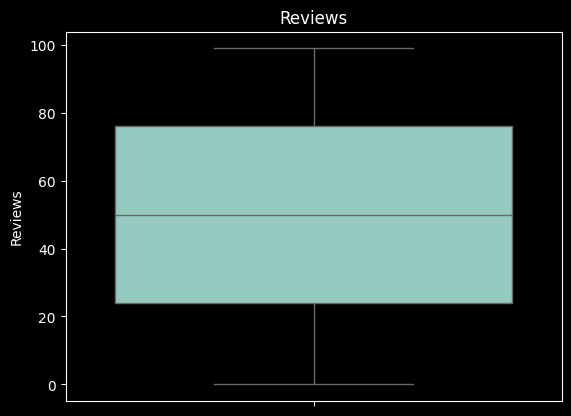

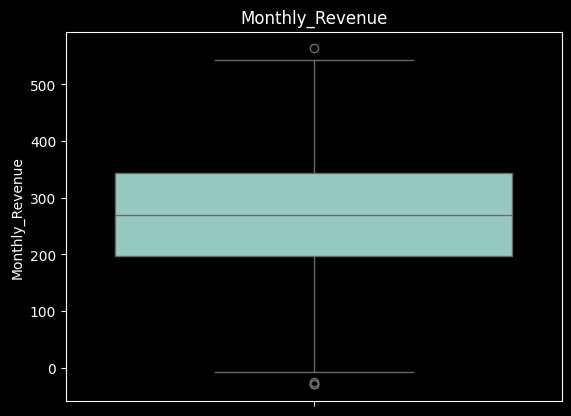

In [12]:
#  Investigating outliers
for col in df.select_dtypes(include="number").columns:
    if col=="Promotions":continue
    sns.boxplot(
        df[col]
    )
    plt.title(col)
    plt.show()

In [13]:
q1=df["Monthly_Revenue"].quantile(0.25)
q2=df["Monthly_Revenue"].quantile(0.75)
IQR=(q2-q1)
a=df["Monthly_Revenue"]>(q2+(1.5*IQR))
df.loc[a]

,Number_of_Customers,Menu_Price,Marketing_Spend,Cuisine_Type,Average_Customer_Spending,Promotions,Reviews,Monthly_Revenue
84,96,16.62082,16.610689,Japanese,12.284687,0,23,563.381332


FIXING DATA PROBLEMS

In [14]:
# create a copy to work on
data=df.copy()


In [15]:
# Fixing impossible values
a=df["Monthly_Revenue"]<0
df.loc[a,"Monthly_Revenue"]=np.nan

In [16]:
#  Missing values after treating impossible values
df.isnull().sum()

Number_of_Customers          0
Menu_Price                   0
Marketing_Spend              0
Cuisine_Type                 0
Average_Customer_Spending    0
Promotions                   0
Reviews                      0
Monthly_Revenue              5
dtype: int64

DATA ANALYSIS

DESCRIPTIVE ANALYSIS

In [17]:
# Numerical analysis
data.describe(include="number")

,Number_of_Customers,Menu_Price,Marketing_Spend,Average_Customer_Spending,Promotions,Reviews,Monthly_Revenue
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,53.271000,30.219120,9.958726,29.477085,0.497000,49.837000,268.724172
std,26.364914,11.278760,5.845586,11.471686,0.500241,29.226334,103.982950
min,10.000000,10.009501,0.003768,10.037177,0.000000,0.000000,-28.977809
25%,30.000000,20.396828,4.690724,19.603041,0.000000,24.000000,197.103642
50%,54.000000,30.860614,10.092047,29.251365,0.000000,50.000000,270.213964
75%,74.000000,39.843868,14.992436,39.553220,1.000000,76.000000,343.395793
max,99.000000,49.974140,19.994276,49.900725,1.000000,99.000000,563.381332


In [18]:
#  Categorical analysis
df.describe(include="str")

,Cuisine_Type
count,1000
unique,4
top,Japanese
freq,262


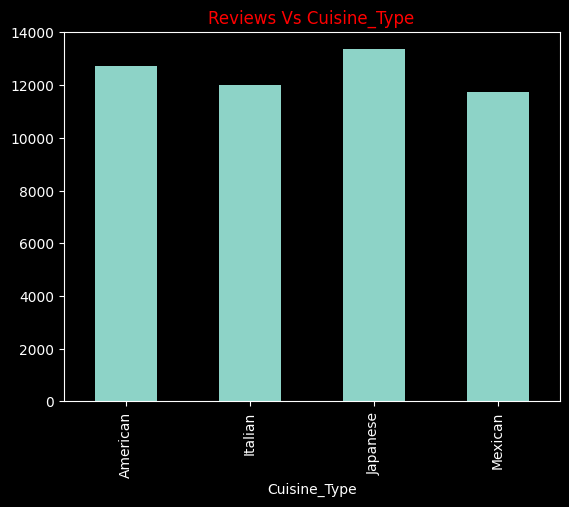

In [19]:
#  Reviews vs Cuisine type
Reviws_Cuisine=data.groupby("Cuisine_Type")["Reviews"].sum()
Reviws_Cuisine.plot(
    kind="bar"
)
plt.title("Reviews Vs Cuisine_Type",color="r")
plt.show()

In [20]:
#  Cuisine Type cost
data.groupby("Cuisine_Type")[["Menu_Price","Number_of_Customers","Marketing_Spend","Average_Customer_Spending"]].max()

,Menu_Price,Number_of_Customers,Marketing_Spend,Average_Customer_Spending
Cuisine_Type,,,,
American,49.907705,99,19.892973,49.751359
Italian,49.974140,99,19.994276,49.820439
Japanese,49.685333,99,19.834852,49.900725
Mexican,49.853431,99,19.922459,49.818966


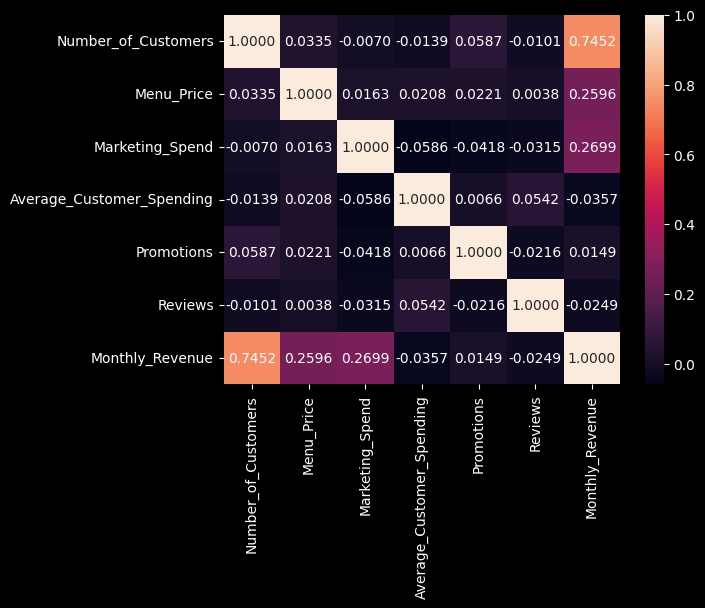

In [21]:
correlation_columns=data.select_dtypes(include="number").columns
corr=data[correlation_columns].corr()
# Heatmap
sns.heatmap(
    corr,
    annot=True,
    fmt=".4f"
    
)
plt.show()

INITIALIZING PIPELINE